# Anchored tabular attention: exploratory 90% accuracy target

This more expressive model combines a frozen, training-fitted Logistic Regression prediction with two learned correction branches:

1. Feature-token self-attention (2 or 3 blocks, 4 heads).
2. A residual MLP (2 or 3 blocks).
3. Learned gates controlling both corrections.

Each output logit is:
**LR logit + gated attention correction + gated residual-MLP correction.**

The correction heads start at zero, so initial predictions match the LR anchor. The model must earn a correction using training data. This is a project-specific hybrid inspired by tabular attention methods, not a published pretrained model or an exact FT-Transformer reproduction.

**90% means accuracy, not AUROC.** It requires at least 531 correct predictions among 589 participants, or 200 among 222. Achieving this is not guaranteed. The notebook does not change labels, remove difficult participants, or optimize against outer held-out outcomes.

Written but not executed or tested by the assistant.


## 1. Locate the project

Use the same environment as the completed MLP/ResNet runs, not the separately pinned TabPFN environment. GPU is recommended for this attention experiment, but CPU is supported. No additional model library is needed.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = None
try:
    from google.colab import drive
except ImportError:
    pass
else:
    drive.mount('/content/drive')
    PROJECT_ROOT = PROJECT_ROOT or '/content/drive/MyDrive/ADNI_capstone'

ROOT = Path(PROJECT_ROOT).expanduser().resolve() if PROJECT_ROOT else next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/scripts/hybrid_models.py').is_file()), None)
if ROOT is None or not (ROOT / 'src/scripts/hybrid_models.py').is_file():
    raise FileNotFoundError('Set PROJECT_ROOT to the updated project folder.')
print('Project:', ROOT)


Project: /Volumes/ColdCache/untitled folder/dddd/Tables_19Sep2026


## 2. Dependencies, only if needed

The dependencies are the same as for MLP/ResNet. Skip this cell when already installed. If installation requests a restart, restart and rerun the setup cell.


In [2]:
requirements_file = str(ROOT / 'requirements-deep-learning.txt')
%pip install -r "{requirements_file}"



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 3. Freeze the protocol before starting

- Preserve the original complete-case cohorts, features, labels, and five outer folds.
- Inside each outer training set, compare two predefined attention/residual configurations on three inner folds.
- Fit preprocessing and each frozen LR anchor only on the relevant inner training participants.
- Use inner validation binary cross-entropy for early stopping and inner out-of-fold log loss for configuration selection.
- Epoch zero is eligible. If the correction does not help inner validation, the selected refit can reduce to the LR anchor.
- Refit the selected configuration from scratch on the full outer training set for the median inner-selected epoch count.
- Report final seeds 42/43/44 and a separate average-probability ensemble. Seed 42 is primary; do not choose the best seed.
- Give Logistic Regression a training-only search over five C values, alongside the original fixed-C reference.
- Keep the threshold at 0.5. Report sensitivity, specificity, calibration, and uncertainty as well as accuracy.

The default workload is 90 inner neural fits plus 45 outer neural refits across the three experiments, and a small Logistic Regression search. There is no automatic search until 90% is obtained.

These are exploratory experiments on already-inspected data. They cannot create an untouched final test set.


In [3]:
import json
import pandas as pd
from IPython.display import display, Markdown, Image
sys.path.insert(0, str(ROOT / 'src/scripts'))
from hybrid_models import run_hybrid
from deep_models import load_data

cfg = json.loads((ROOT / 'config/hybrid_attention.json').read_text())
REPORT = ROOT / 'reports/modeling' / cfg['run_name']
manifest, cohorts = load_data(cfg)
display(pd.DataFrame([
    {'experiment': name, 'participants': len(frame), 'converters': int(frame.label.sum()),
     'correct_needed_for_90_percent': (9 * len(frame) + 9) // 10}
    for name, frame in cohorts.items()
]))
print(json.dumps(cfg, indent=2))


,experiment,participants,converters,correct_needed_for_90_percent
0,clinical_reference,589,216,531
1,matched_clinical,222,118,200
2,matched_fusion,222,118,200


{
  "baseline_run": "artifacts/modeling/complete_cases",
  "run_name": "hybrid_attention_v1",
  "experiments": [
    "clinical_reference",
    "matched_clinical",
    "matched_fusion"
  ],
  "seeds": [
    42,
    43,
    44
  ],
  "seed": 42,
  "inner_folds": 3,
  "threshold": 0.5,
  "target_accuracy": 0.9,
  "bootstrap_repetitions": 1000,
  "device": "auto",
  "torch_threads": 1,
  "training": {
    "learning_rate": 0.0005,
    "batch_size": 32,
    "max_epochs": 400,
    "patience": 35,
    "min_delta": 0.0001,
    "gradient_clip": 1.0,
    "correction_penalty": 0.01
  },
  "lr_C_candidates": [
    1.0,
    0.1,
    0.3,
    3.0,
    10.0
  ],
  "candidates": [
    {
      "name": "attention32",
      "token_width": 32,
      "attention_blocks": 2,
      "heads": 4,
      "residual_width": 64,
      "residual_blocks": 2,
      "dropout": 0.25,
      "learning_rate": 0.0005,
      "weight_decay": 0.001
    },
    {
      "name": "attention48",
      "token_width": 48,
      "attentio

## 4. Run the experiment

This cell fits the models. Existing directories are protected from overwrite; change run_name before an intentional new run. If revisiting a completed run, skip this cell and display the existing reports.

Original baselines, voting, neural results, show_result.md, and the hardcoded comparison notebook are not modified.


In [4]:
results = run_hybrid(cfg)


Hybrid attention: clinical_reference, outer fold 1/5
  Inner fold 1: attention32
  Inner fold 1: attention48
  Inner fold 2: attention32
  Inner fold 2: attention48
  Inner fold 3: attention32
  Inner fold 3: attention48
Hybrid attention: clinical_reference, outer fold 2/5
  Inner fold 1: attention32
  Inner fold 1: attention48
  Inner fold 2: attention32
  Inner fold 2: attention48
  Inner fold 3: attention32
  Inner fold 3: attention48
Hybrid attention: clinical_reference, outer fold 3/5
  Inner fold 1: attention32
  Inner fold 1: attention48
  Inner fold 2: attention32
  Inner fold 2: attention48
  Inner fold 3: attention32
  Inner fold 3: attention48
Hybrid attention: clinical_reference, outer fold 4/5
  Inner fold 1: attention32
  Inner fold 1: attention48
  Inner fold 2: attention32
  Inner fold 2: attention48
  Inner fold 3: attention32
  Inner fold 3: attention48
Hybrid attention: clinical_reference, outer fold 5/5
  Inner fold 1: attention32
  Inner fold 1: attention48
  Inner

## 5. Complete results and the target

There are six rows per cohort: original fixed-C LR, tuned LR, three hybrid seeds, and the hybrid seed-average ensemble. A “reached target” value is descriptive; it is not a guarantee of performance on new patients.

If the target is not reached, retain that result. Do not select an unusually successful fold or seed and present it as overall performance.


In [5]:
results = pd.read_csv(REPORT / 'metrics.csv')
columns = ['experiment', 'model', 'participants', 'accuracy', 'precision', 'sensitivity',
           'specificity', 'f1', 'balanced_accuracy', 'auroc', 'average_precision', 'brier_score']
formats = {c: '{:.1%}' for c in ['accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'balanced_accuracy']}
formats.update({c: '{:.3f}' for c in ['auroc', 'average_precision', 'brier_score']})
display(results[columns].style.format(formats))
display(results[['experiment', 'model', 'tn', 'fp', 'fn', 'tp']])
display(pd.read_csv(REPORT / 'target_summary.csv'))
display(pd.read_csv(REPORT / 'seed_variability.csv').round(4))


,experiment,model,participants,accuracy,precision,sensitivity,specificity,f1,balanced_accuracy,auroc,average_precision,brier_score
0,clinical_reference,logistic_regression,589,84.4%,81.0%,75.0%,89.8%,77.9%,82.4%,0.912,0.852,0.110
1,clinical_reference,tuned_logistic_regression,589,85.2%,82.1%,76.4%,90.3%,79.1%,83.4%,0.912,0.853,0.111
2,clinical_reference,hybrid_seed42,589,84.9%,81.9%,75.5%,90.3%,78.6%,82.9%,0.909,0.848,0.111
3,clinical_reference,hybrid_seed43,589,83.9%,81.0%,73.1%,90.1%,76.9%,81.6%,0.909,0.848,0.112
4,clinical_reference,hybrid_seed44,589,84.9%,82.6%,74.5%,90.9%,78.3%,82.7%,0.911,0.850,0.110
5,clinical_reference,hybrid_seed_mean,589,84.6%,81.7%,74.5%,90.3%,78.0%,82.4%,0.910,0.850,0.110
6,matched_clinical,logistic_regression,222,80.6%,81.5%,82.2%,78.8%,81.9%,80.5%,0.898,0.917,0.130
7,matched_clinical,tuned_logistic_regression,222,81.1%,81.1%,83.9%,77.9%,82.5%,80.9%,0.896,0.914,0.132
8,matched_clinical,hybrid_seed42,222,79.3%,81.0%,79.7%,78.8%,80.3%,79.3%,0.881,0.897,0.144
9,matched_clinical,hybrid_seed43,222,80.2%,81.4%,81.4%,78.8%,81.4%,80.1%,0.887,0.906,0.139


,experiment,model,tn,fp,fn,tp
0,clinical_reference,logistic_regression,335,38,54,162
1,clinical_reference,tuned_logistic_regression,337,36,51,165
2,clinical_reference,hybrid_seed42,337,36,53,163
3,clinical_reference,hybrid_seed43,336,37,58,158
4,clinical_reference,hybrid_seed44,339,34,55,161
5,clinical_reference,hybrid_seed_mean,337,36,55,161
6,matched_clinical,logistic_regression,82,22,21,97
7,matched_clinical,tuned_logistic_regression,81,23,19,99
8,matched_clinical,hybrid_seed42,82,22,24,94
9,matched_clinical,hybrid_seed43,82,22,22,96


,experiment,model,participants,accuracy,sensitivity,specificity,target_accuracy,reached_target
0,clinical_reference,logistic_regression,589,0.843803,0.750000,0.898123,0.9,False
1,clinical_reference,tuned_logistic_regression,589,0.852292,0.763889,0.903485,0.9,False
2,clinical_reference,hybrid_seed42,589,0.848896,0.754630,0.903485,0.9,False
3,clinical_reference,hybrid_seed43,589,0.838710,0.731481,0.900804,0.9,False
4,clinical_reference,hybrid_seed44,589,0.848896,0.745370,0.908847,0.9,False
5,clinical_reference,hybrid_seed_mean,589,0.845501,0.745370,0.903485,0.9,False
6,matched_clinical,logistic_regression,222,0.806306,0.822034,0.788462,0.9,False
7,matched_clinical,tuned_logistic_regression,222,0.810811,0.838983,0.778846,0.9,False
8,matched_clinical,hybrid_seed42,222,0.792793,0.796610,0.788462,0.9,False
9,matched_clinical,hybrid_seed43,222,0.801802,0.813559,0.788462,0.9,False


,experiment,metric,mean,std,min,max
0,clinical_reference,accuracy,0.8455,0.0059,0.8387,0.8489
1,clinical_reference,auroc,0.9096,0.0009,0.9089,0.9106
2,clinical_reference,average_precision,0.8491,0.0011,0.8485,0.8504
3,clinical_reference,brier_score,0.1109,0.0010,0.1098,0.1119
4,clinical_reference,sensitivity,0.7438,0.0117,0.7315,0.7546
5,clinical_reference,specificity,0.9044,0.0041,0.9008,0.9088
6,matched_clinical,accuracy,0.8018,0.0090,0.7928,0.8108
7,matched_clinical,auroc,0.8881,0.0078,0.8806,0.8962
8,matched_clinical,average_precision,0.9046,0.0073,0.8968,0.9114
9,matched_clinical,brier_score,0.1383,0.0061,0.1317,0.1437


## 6. Compare fairly against both LR references

The original fixed-C reference shows changes against the earlier design. The tuned LR reference accounts for some benefit of giving the hybrid a search budget.

Paired differences use the same held-out participants. Positive accuracy/AUROC/AP and negative Brier favor the hybrid. Intervals spanning zero leave the change uncertain under this conditional bootstrap. These intervals do not capture all retraining uncertainty and are not adjusted for multiple comparisons.


**Against original fixed-C Logistic Regression**

,experiment,model,reference,metric,difference,lower_95,upper_95,bootstrap_samples
0,clinical_reference,hybrid_seed42,logistic_regression,auroc,-0.0028,-0.0072,0.0014,1000
1,clinical_reference,hybrid_seed42,logistic_regression,average_precision,-0.0035,-0.0097,0.0034,1000
2,clinical_reference,hybrid_seed42,logistic_regression,brier_score,0.0012,-0.0023,0.0044,1000
3,clinical_reference,hybrid_seed42,logistic_regression,accuracy,0.0051,-0.0085,0.0187,1000
4,clinical_reference,hybrid_seed_mean,logistic_regression,auroc,-0.0020,-0.0055,0.0017,1000
5,clinical_reference,hybrid_seed_mean,logistic_regression,average_precision,-0.0019,-0.0076,0.0046,1000
6,clinical_reference,hybrid_seed_mean,logistic_regression,brier_score,0.0005,-0.0024,0.0034,1000
7,clinical_reference,hybrid_seed_mean,logistic_regression,accuracy,0.0017,-0.0102,0.0136,1000
8,matched_clinical,hybrid_seed42,logistic_regression,auroc,-0.0176,-0.0350,-0.0020,1000
9,matched_clinical,hybrid_seed42,logistic_regression,average_precision,-0.0204,-0.0401,-0.0036,1000


**Against training-tuned Logistic Regression**

,experiment,model,reference,metric,difference,lower_95,upper_95,bootstrap_samples
0,clinical_reference,hybrid_seed42,tuned_logistic_regression,auroc,-0.0031,-0.0083,0.0022,1000
1,clinical_reference,hybrid_seed42,tuned_logistic_regression,average_precision,-0.0045,-0.0125,0.0033,1000
2,clinical_reference,hybrid_seed42,tuned_logistic_regression,brier_score,-0.0001,-0.0042,0.0044,1000
3,clinical_reference,hybrid_seed42,tuned_logistic_regression,accuracy,-0.0034,-0.0187,0.0136,1000
4,clinical_reference,hybrid_seed_mean,tuned_logistic_regression,auroc,-0.0022,-0.0071,0.0027,1000
5,clinical_reference,hybrid_seed_mean,tuned_logistic_regression,average_precision,-0.0029,-0.0095,0.0043,1000
6,clinical_reference,hybrid_seed_mean,tuned_logistic_regression,brier_score,-0.0008,-0.0046,0.0033,1000
7,clinical_reference,hybrid_seed_mean,tuned_logistic_regression,accuracy,-0.0068,-0.0204,0.0068,1000
8,matched_clinical,hybrid_seed42,tuned_logistic_regression,auroc,-0.0157,-0.0363,0.0032,1000
9,matched_clinical,hybrid_seed42,tuned_logistic_regression,average_precision,-0.0172,-0.0374,0.0011,1000


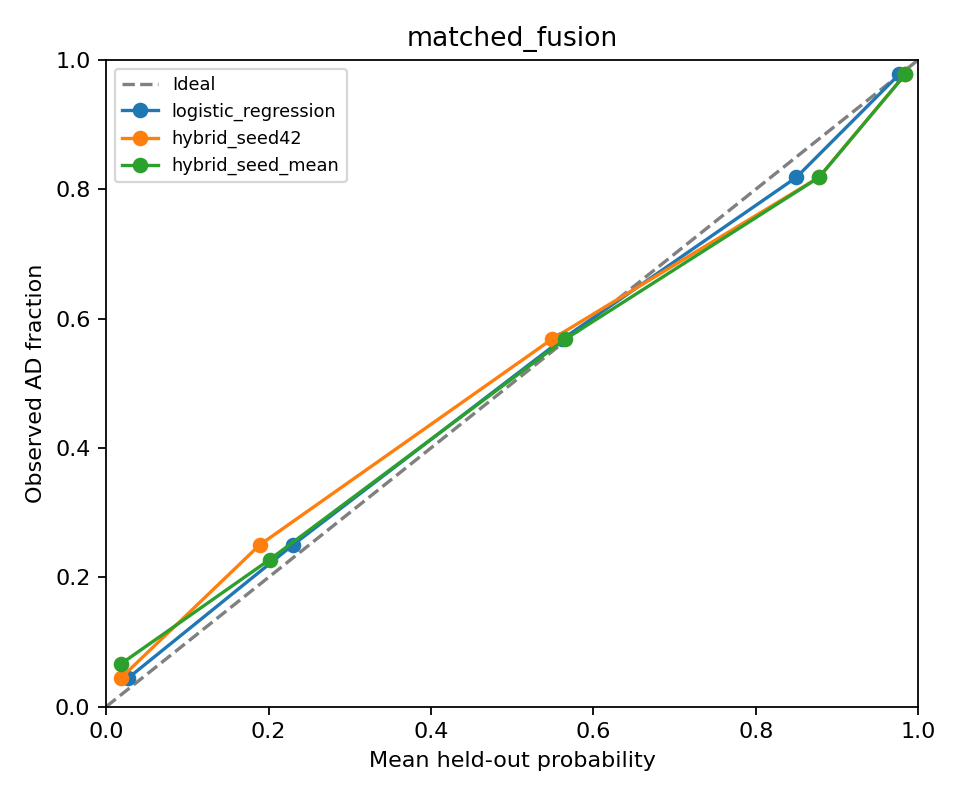

In [6]:
display(Markdown('**Against original fixed-C Logistic Regression**'))
display(pd.read_csv(REPORT / 'paired_vs_logistic.csv').round(4))
display(Markdown('**Against training-tuned Logistic Regression**'))
display(pd.read_csv(REPORT / 'paired_vs_tuned_logistic.csv').round(4))
display(Image(filename=str(REPORT / 'calibration_matched_fusion.png')))


## 7. What actually got selected?

The recorded parameter count reflects the actual model and encoded input width. Gates describe how strongly the correction branches contribute; they are not feature importance or causal explanations.

A refit epoch count of zero means inner validation did not justify departing from the LR anchor. That outcome must be reported explicitly.


In [7]:
display(pd.read_csv(REPORT / 'selected_models.csv'))
display(pd.read_csv(REPORT / 'search_results.csv').round(5))
display(Markdown((REPORT / 'results.md').read_text()))


,experiment,outer_fold,seed,candidate,refit_epochs,anchor_only,tuned_lr_C,trainable_parameters,attention_gate,residual_gate
0,clinical_reference,1,42,attention32,9,False,0.1,61508,0.118820,0.125186
1,clinical_reference,1,43,attention32,9,False,0.1,61508,0.117980,0.125107
2,clinical_reference,1,44,attention32,9,False,0.1,61508,0.117933,0.126044
3,clinical_reference,2,42,attention32,15,False,0.1,61508,0.123400,0.135759
4,clinical_reference,2,43,attention32,15,False,0.1,61508,0.123361,0.135701
5,clinical_reference,2,44,attention32,15,False,0.1,61508,0.126821,0.135104
6,clinical_reference,3,42,attention32,14,False,0.3,61508,0.124108,0.132188
7,clinical_reference,3,43,attention32,14,False,0.3,61508,0.124660,0.133624
8,clinical_reference,3,44,attention32,14,False,0.3,61508,0.124085,0.132911
9,clinical_reference,4,42,attention32,13,False,0.1,61508,0.120867,0.130845


,experiment,outer_fold,family,candidate,inner_log_loss,selected,inner_best_epochs
0,clinical_reference,1,hybrid,attention32,0.39006,True,"[0, 9, 11]"
1,clinical_reference,1,hybrid,attention48,0.39027,False,"[0, 9, 9]"
2,clinical_reference,1,logistic,1.0,0.39056,False,NaN
3,clinical_reference,1,logistic,0.1,0.37311,True,NaN
4,clinical_reference,1,logistic,0.3,0.37904,False,NaN
...,...,...,...,...,...,...,...
100,matched_fusion,5,logistic,1.0,0.40857,False,NaN
101,matched_fusion,5,logistic,0.1,0.42016,False,NaN
102,matched_fusion,5,logistic,0.3,0.40329,True,NaN
103,matched_fusion,5,logistic,3.0,0.42561,False,NaN


# Exploratory anchored-attention results

**90% accuracy is a target, not an assumed outcome.** All rows below use held-out predictions at threshold 0.5.

| Experiment | Model | N | Accuracy | AUROC | AP | Brier | Reached 90%? |
|---|---|---:|---:|---:|---:|---:|---|
| clinical_reference | logistic_regression | 589 | 84.4% | 0.912 | 0.852 | 0.110 | No |
| clinical_reference | tuned_logistic_regression | 589 | 85.2% | 0.912 | 0.853 | 0.111 | No |
| clinical_reference | hybrid_seed42 | 589 | 84.9% | 0.909 | 0.848 | 0.111 | No |
| clinical_reference | hybrid_seed43 | 589 | 83.9% | 0.909 | 0.848 | 0.112 | No |
| clinical_reference | hybrid_seed44 | 589 | 84.9% | 0.911 | 0.850 | 0.110 | No |
| clinical_reference | hybrid_seed_mean | 589 | 84.6% | 0.910 | 0.850 | 0.110 | No |
| matched_clinical | logistic_regression | 222 | 80.6% | 0.898 | 0.917 | 0.130 | No |
| matched_clinical | tuned_logistic_regression | 222 | 81.1% | 0.896 | 0.914 | 0.132 | No |
| matched_clinical | hybrid_seed42 | 222 | 79.3% | 0.881 | 0.897 | 0.144 | No |
| matched_clinical | hybrid_seed43 | 222 | 80.2% | 0.887 | 0.906 | 0.139 | No |
| matched_clinical | hybrid_seed44 | 222 | 81.1% | 0.896 | 0.911 | 0.132 | No |
| matched_clinical | hybrid_seed_mean | 222 | 80.6% | 0.894 | 0.909 | 0.134 | No |
| matched_fusion | logistic_regression | 222 | 83.8% | 0.906 | 0.919 | 0.124 | No |
| matched_fusion | tuned_logistic_regression | 222 | 82.9% | 0.903 | 0.914 | 0.125 | No |
| matched_fusion | hybrid_seed42 | 222 | 82.0% | 0.904 | 0.919 | 0.126 | No |
| matched_fusion | hybrid_seed43 | 222 | 82.0% | 0.904 | 0.918 | 0.126 | No |
| matched_fusion | hybrid_seed44 | 222 | 79.7% | 0.894 | 0.909 | 0.134 | No |
| matched_fusion | hybrid_seed_mean | 222 | 82.0% | 0.903 | 0.918 | 0.127 | No |

## Protocol and interpretation

- Original cohorts, labels, features, and five outer folds are unchanged. These already-inspected data support exploratory conclusions only.
- The frozen LR anchor is fitted only on the relevant training partition. Attention and residual-MLP branches learn gated logit corrections.
- Two neural configurations are selected by inner-fold log loss using the configured tuning seed. Inner validation also selects stopping epochs; the median chosen epoch is used for full outer-training refits.
- Epoch zero is eligible. If corrections do not help inner validation, the refit can reduce to the LR anchor. This is reported explicitly, not presented as a neural gain.
- Seeds 42/43/44 are all reported; the first configured seed is primary. seed_mean averages probabilities and is a separate ensemble.
- Tuned Logistic Regression gets its own training-only C search. Compare against it as well as the original fixed-C reference.
- Accuracy is not optimized by changing the outer threshold, dropping difficult participants, or inspecting outer labels during tuning.
- AP is non-interpolated average precision; lower Brier is better. Check sensitivity, specificity, and calibration alongside accuracy.
- Paired bootstrap intervals condition on saved predictions, omit full retraining uncertainty, and are not corrected for multiple comparisons.
- A point estimate above 90% on these data would not establish external performance or clinical readiness. Do not choose the best seed post hoc.
- Matched participants are ADNI1 only. Complete-case selection, unresolved outcomes, the provisional endpoint, and unavailable MRI/CSF comparisons remain limitations.


## What to share

Share `metrics.csv`, `target_summary.csv`, `paired_vs_logistic.csv`, `paired_vs_tuned_logistic.csv`, and `selected_models.csv` from the report folder. The private participant predictions and model weights do not need to be uploaded merely to summarize results.

No participant-level features were selected from outer-fold SHAP rankings, and no sample was dropped to improve accuracy. The design is motivated by the previously observed strength of LR; that adaptive choice makes the follow-up exploratory.

MRI/CSF limitations, complete-case selection, the provisional endpoint, the ADNI1-only matched cohort, and absence of external validation remain. More complexity may fail to help. Attention weights are not a substitute for a validated explainability analysis.
